<a href="https://colab.research.google.com/github/Abhi20076/Abhishek_chaudhary_HCL-Project/blob/main/Abhishek_Chaudhary_Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Dice Roll and Probability Simulator using Python
**Name:** Abhishek Chaudhary  
**Roll No.:** 2026B15310366  
**Branch & Sem:** B.Tech CSE (AI & ML) – Sem 1  
**College:** ABES Engineering College, Ghaziabad  
**Program:** HCLTech 5-Day Training (Data Analytics Group)
**Git hub link:**https://github.com/Abhi20076/Abhishek_chaudhary_HCL-Project.git

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

num_rolls = int(input("How many times do you want to roll the 2 dice? (e.g. 10000): "))

# Roll two dice using NumPy (1 to 6; 7 is excluded in NumPy randint)
die1 = np.random.randint(1, 7, size=num_rolls)
die2 = np.random.randint(1, 7, size=num_rolls)
total = die1 + die2

# Store in a Pandas DataFrame
df = pd.DataFrame({
    "Roll_No": np.arange(1, num_rolls + 1),
    "Die_1": die1,
    "Die_2": die2,
    "Sum": total
})

# Save dataset to CSV
df.to_csv("dice_roll_dataset.csv", index=False)

print("\nDataset saved as dice_roll_dataset.csv")
print(df.head())
print(f"\nExperimental Average Sum : {np.mean(total):.2f}")
print("Theoretical Average Sum  : 7.00")

How many times do you want to roll the 2 dice? (e.g. 10000): 10000

Dataset saved as dice_roll_dataset.csv
   Roll_No  Die_1  Die_2  Sum
0        1      6      2    8
1        2      1      5    6
2        3      4      2    6
3        4      5      4    9
4        5      2      4    6

Experimental Average Sum : 6.99
Theoretical Average Sum  : 7.00


In [47]:
# Count how many times each sum appeared using Pandas
counts = df["Sum"].value_counts().sort_index()

# Exact theoretical ways out of 36
ways = {i: 0 for i in range(2, 13)}
for d1 in range(1, 7):
    for d2 in range(1, 7):
        ways[d1 + d2] += 1

# Create a comparison DataFrame
summary = pd.DataFrame({
    "Sum": range(2, 13),
    "Count": [counts.get(s, 0) for s in range(2, 13)],
    "Ways_out_of_36": [ways[s] for s in range(2, 13)]
})

summary["Experimental_%"] = (summary["Count"] / num_rolls) * 100
summary["Theoretical_%"] = (summary["Ways_out_of_36"] / 36) * 100

print(summary.round(2).to_string(index=False))

 Sum  Count  Ways_out_of_36  Experimental_%  Theoretical_%
   2    308               1            3.08           2.78
   3    597               2            5.97           5.56
   4    825               3            8.25           8.33
   5   1046               4           10.46          11.11
   6   1387               5           13.87          13.89
   7   1637               6           16.37          16.67
   8   1431               5           14.31          13.89
   9   1106               4           11.06          11.11
  10    821               3            8.21           8.33
  11    573               2            5.73           5.56
  12    269               1            2.69           2.78


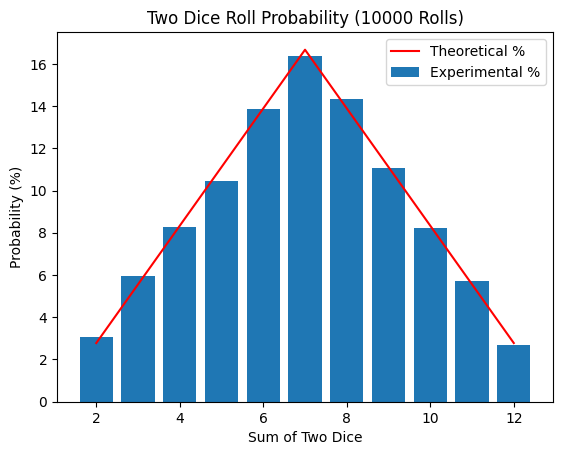

In [48]:
# Simple bar chart for experimental % and line for theoretical %
plt.bar(summary["Sum"], summary["Experimental_%"], label="Experimental %")
plt.plot(summary["Sum"], summary["Theoretical_%"], color="red", label="Theoretical %")

plt.title(f"Two Dice Roll Probability ({num_rolls} Rolls)")
plt.xlabel("Sum of Two Dice")
plt.ylabel("Probability (%)")
plt.legend()
plt.show()

In [49]:
target = int(input("Enter a target sum (2 to 12) to check probability of getting that sum or higher: "))

if target < 2 or target > 12:
    print("Please enter a number between 2 and 12.")
else:
    # Filter rows using Pandas
    exp_prob = (len(df[df["Sum"] >= target]) / num_rolls) * 100
    theo_prob = (summary[summary["Sum"] >= target]["Ways_out_of_36"].sum() / 36) * 100

    print(f"\nChance of getting sum >= {target}:")
    print(f"Experimental : {exp_prob:.2f}%")
    print(f"Theoretical  : {theo_prob:.2f}%")

Enter a target sum (2 to 12) to check probability of getting that sum or higher: 9

Chance of getting sum >= 9:
Experimental : 27.69%
Theoretical  : 27.78%


In [50]:
import random
import pandas as pd
from google.colab import files

rows = []
for roll_no in range(1, 10001):
    die1 = random.randint(1, 6)
    die2 = random.randint(1, 6)
    rows.append([roll_no, die1, die2, die1 + die2])

df = pd.DataFrame(rows, columns=["Roll_No", "Die_1", "Die_2", "Sum"])
df.to_csv("dice_roll_dataset.csv", index=False)
files.download("dice_roll_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>